# Exercise 3
## HOG Features and Classical Machine Learning
- Implement a traditional computer vision approach using Histogram of Oriented Gradients
(HOG) features combined with standard machine learning classifiers, first on Dataset 1
and then on Dataset 2.
- Your implementation should include feature extraction, model selection, and performance
evaluation
- Provide the relevant Phyton code and a report in which you describe and discuss your
work, especially how performance may vary depending on the dataset 1 or 2.

### Imports

In [1]:
import os
from skimage.feature import hog
from skimage.io import imread
from skimage.transform import resize
from skimage.color import rgb2gray
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_files
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay, confusion_matrix

### Loading and Labeling of both datasets

#### Datasets paths

In [2]:
# Set dataset path as current working directory
datasets_path = os.getcwd() # Assuming datasets are in the current working directory

# Fetal brain dataset
brain_path = os.path.join(datasets_path, "Classification_planes")

# For brain dataset
brain_path = os.path.join(datasets_path, "brain_planes")


#### Loading function

In [3]:
import os
from PIL import Image
import numpy as np
from pathlib import Path

def load_images(folder: str, label: int, target_size=(128, 128), max_images=None, 
                extensions=('.jpg', '.jpeg', '.png', '.bmp', '.tiff')) -> list:
    """
    Load images from folder, resize them, and assign label.
    
    Args:
        folder: Path to folder with images
        label: Numeric label for all images in this folder
        target_size: Resize images to this size (width, height)
        max_images: Max number of images to load (None = all)
        extensions: Image file extensions to load
    
    Returns:
        List of (image_array, label) tuples
    """
    # Define path
    folder_path = Path(folder)
    
    # Find all image files in folder
    print(f"Searching images in: {folder}")
    image_files = []
    for ext in extensions:
        # Search for files with lowercase and uppercase extensions
        image_files.extend(folder_path.glob(f"*{ext.lower()}"))
        image_files.extend(folder_path.glob(f"*{ext.upper()}"))
    
    # Remove duplicates and sort files alphabetically
    image_files = sorted(list(set(image_files)))
    
    # Limit number of images if requested
    if max_images:
        image_files = image_files[:max_images]
    
    print(f"Found {len(image_files)} images to load")
    
    # Load each image
    data = []  # List to store (image, label) pairs
    for img_path in image_files:
        # Open image file
        with Image.open(img_path) as img:
            
            # Convert to grayscale if not already
            img = img.convert("L")

            # Resize image to target size
            img = img.resize(target_size, Image.Resampling.LANCZOS)
                
            # Convert to numpy array
            img_array = np.array(img)
                
            # Store image and its label
            data.append((img_array, label))
    
    print(f"Loaded {len(data)} images successfully")
    return data


#### Dataset 1: Fetal Ultrasound Classification

In [4]:
# Load all images
ultrasound_data = []
for folder, label in [("Classification_planes/Maternal cervix", 0),
                      ("Classification_planes/Fetal thorax", 1),
                      ("Classification_planes/Fetal brain", 2)]:
    ultrasound_data.extend(load_images(folder, label, max_images=None))

# Convert to DataFrame
df_ultrasound = pd.DataFrame(ultrasound_data, columns=['image', 'target'])


Searching images in: Classification_planes/Maternal cervix
Found 981 images to load
Loaded 981 images successfully
Searching images in: Classification_planes/Fetal thorax
Found 1058 images to load
Loaded 1058 images successfully
Searching images in: Classification_planes/Fetal brain
Found 1620 images to load
Loaded 1620 images successfully


In [7]:
# Display first few entries of the DataFrame
df_ultrasound.head()

,image,target
0,"[[82, 63, 71, 61, 62, 45, 62, 75, 30, 27, 37, ...",0
1,"[[3, 2, 0, 0, 1, 2, 2, 6, 1, 6, 11, 3, 3, 3, 3...",0
2,"[[3, 2, 0, 0, 1, 2, 2, 6, 1, 6, 11, 3, 3, 3, 3...",0
3,"[[3, 2, 0, 0, 1, 2, 2, 6, 1, 6, 11, 3, 3, 3, 3...",0
4,"[[179, 144, 107, 92, 67, 74, 123, 126, 80, 97,...",0


Image shape: (128, 128)
Label: 0


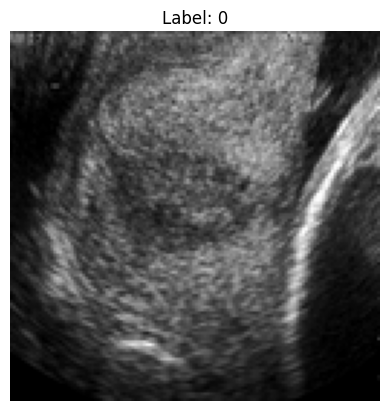

In [8]:
# Display first image and its label to assess correct loading of df_ultrasound

# Take first image
img_array = df_ultrasound.loc[0, "image"]
label = df_ultrasound.loc[0, "target"]

print("Image shape:", img_array.shape)
print("Label:", label)

plt.imshow(img_array, cmap="gray")
plt.title(f"Label: {label}")
plt.axis("off")
plt.show()


#### Dataset 2: Fetal Brain Standard Planes

In [5]:
# Load all images
brain_data = []
for folder, label in [("brain_planes/Trans-ventricular", 0),
                      ("brain_planes/Trans-thalamic", 1),
                      ("brain_planes/Trans-cerebellum", 2)]:
    brain_data.extend(load_images(folder, label, max_images=None))

# Convert to DataFrame
df_brain = pd.DataFrame(brain_data, columns=['image', 'target'])

Searching images in: brain_planes/Trans-ventricular
Found 590 images to load
Loaded 590 images successfully
Searching images in: brain_planes/Trans-thalamic
Found 1636 images to load
Loaded 1636 images successfully
Searching images in: brain_planes/Trans-cerebellum
Found 708 images to load
Loaded 708 images successfully


In [10]:
# Display first few entries of the DataFrame
df_brain.head()

,image,target
0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",0
1,"[[4, 4, 4, 1, 0, 4, 4, 4, 4, 7, 11, 5, 7, 7, 8...",0
2,"[[2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,...",0
3,"[[2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,...",0
4,"[[17, 8, 8, 12, 14, 10, 6, 6, 10, 14, 25, 49, ...",0


Image shape: (128, 128)
Label: 0


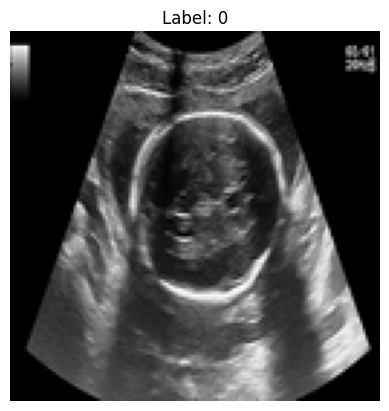

In [11]:
# Display first image and its label to assess correct loading of df_brain

# Take first image
img_array = df_brain.loc[0, "image"]
label = df_brain.loc[0, "target"]

print("Image shape:", img_array.shape)
print("Label:", label)

plt.imshow(img_array, cmap="gray")
plt.title(f"Label: {label}")
plt.axis("off")
plt.show()

### Balancing the datasets

In [6]:
# DATASET 1

# Balance the ultrasound dataset by undersampling to 981 images per class (i.e. the size of the smallest class)
df_ultrasound_balanced = (
    df_ultrasound[df_ultrasound['target'].isin([0, 1, 2])]
    .groupby('target')
    .sample(n=981, random_state=456, replace=False)
    .reset_index(drop=True)   
)

df_ultrasound_balanced['target'].value_counts()

target
0    981
1    981
2    981
Name: count, dtype: int64

In [7]:
# DATASET 2

# Balance the brain dataset by undersampling to 590 images per class (i.e. the size of the smallest class)
df_brain_balanced = (
    df_brain[df_brain['target'].isin([0, 1, 2])]
    .groupby('target')
    .sample(n=590, random_state=456, replace=False)
    .reset_index(drop=True)
)

df_brain_balanced['target'].value_counts()

target
0    590
1    590
2    590
Name: count, dtype: int64

### HOG feature extraction

In [8]:
# DATASET 1

# HOG feature extraction for the balanced ultrasound dataset
Xhog_ultrasound = []
for img in df_ultrasound_balanced['image']:
    feat = hog(
        img,
        orientations=9,             # 9 directions of gradients
        pixels_per_cell=(16, 16),   # 16x16 pixel cell
        cells_per_block=(2, 2),     # 2 cells blocks
        block_norm="L2-Hys",        # normalization
    ) 
    Xhog_ultrasound.append(feat)

# Conversion to dataframe
df_hog_ultrasound = pd.DataFrame(Xhog_ultrasound)

print("Shape di Xhog for the ultrasound dataframe (observations, features):", df_hog_ultrasound.shape)

Shape di Xhog for the ultrasound dataframe (observations, features): (2943, 1764)


In [9]:
# DATASET 2

# HOG feature extraction for the balanced brain dataset
Xhog_brain = []
for img in df_brain_balanced['image']:
    feat = hog(
        img,
        orientations=9,             # 9 directions of gradients
        pixels_per_cell=(16, 16),   # 16x16 pixel cell
        cells_per_block=(2, 2),     # 2 cells blocks
        block_norm="L2-Hys",        # normalization
    ) 
    Xhog_brain.append(feat)

# Conversion to dataframe
df_hog_brain = pd.DataFrame(Xhog_brain)

Xhog_brain = np.array(Xhog_brain)
print("Shape di Xhog for the brain dataframe (observations, features):", df_hog_brain.shape)

Shape di Xhog for the brain dataframe (observations, features): (1770, 1764)


### Scaling the features

In [ ]:
# DATASET 1

# Features = all HOG features for ultrasound dataset
X_ultrasound = df_hog_ultrasound.values   

# Target = takes labels from the dataframe 
y_ultrasound = df_ultrasound_balanced["target"].reset_index(drop=True)

# Scale only the feature matrix
scaler = StandardScaler()
X_ultrasound_scaled = scaler.fit_transform(X_ultrasound)

# Rebuild final dataframe with scaled features + target column
df_ultrasound_scaled = pd.DataFrame(X_ultrasound_scaled, columns=df_hog_ultrasound.columns)
df_ultrasound_scaled["target"] = y_ultrasound

df_ultrasound_scaled.head()

,0,1,2,3,4,5,6,7,8,9,...,1755,1756,1757,1758,1759,1760,1761,1762,1763,target
0,-0.582499,0.160547,-0.187896,0.020944,-0.292415,-0.266335,-0.225453,1.034355,1.350565,0.339202,...,-1.031267,-0.885468,-1.007400,-0.855689,-0.948994,-0.727596,-0.701022,-0.674452,-0.689996,0
1,-2.289672,-0.034584,2.096694,2.543189,-0.706447,-0.451871,-0.059673,-0.433152,-0.916944,-0.740108,...,-0.885811,-0.885468,-1.007002,-0.855689,-0.657102,-0.727596,-0.701022,-0.674452,-0.689996,0
2,-1.292129,-0.386147,0.313661,0.299595,-0.452712,-0.694270,-0.182870,0.206951,0.589493,0.525174,...,-1.031267,-0.885468,-1.011748,-0.855689,-0.952809,-0.727596,-0.701022,-0.674452,-0.689996,0
3,-0.316397,-0.652172,-0.793200,-0.717854,-1.335019,-0.806613,-0.882322,-1.067645,-0.649791,-0.866945,...,-1.031267,-0.885468,-1.011748,-0.855689,-0.952809,-0.727596,-0.701022,-0.674452,-0.689996,0
4,0.287361,0.565790,3.315566,1.627464,-1.212094,-0.431364,-0.691876,0.462768,1.029629,-0.482396,...,1.626281,0.521371,1.318406,0.217187,1.517306,0.654707,1.903689,-0.050351,-0.442424,0


In [ ]:
# DATASET 2

# Features = all HOG features for brain dataset
X_brain = df_hog_brain.values   

# Target = takes labels from the dataframe
y_brain = df_brain_balanced["target"].reset_index(drop=True)

# Scale only the feature matrix
scaler = StandardScaler()   
X_brain_scaled = scaler.fit_transform(X_brain)

# Rebuild final dataframe with scaled features + target column
df_brain_scaled = pd.DataFrame(X_brain_scaled, columns=df_hog_brain.columns)
df_brain_scaled["target"] = y_brain

df_brain_scaled.head()

,0,1,2,3,4,5,6,7,8,9,...,1755,1756,1757,1758,1759,1760,1761,1762,1763,target
0,0.030595,0.025559,-0.877904,1.261400,0.391809,0.652030,-0.412833,-0.811063,1.008568,-1.247375,...,0.828580,0.937437,0.522363,0.451731,0.844660,0.360150,0.655643,0.498152,0.739674,0
1,1.279003,2.694864,-0.930988,1.418304,1.533630,2.806498,0.163088,1.257350,-1.572959,-1.721499,...,-1.653095,-1.425183,0.036675,-1.224967,-1.439646,-1.147603,-1.130210,-0.993116,-0.977177,0
2,0.119199,-0.950500,-0.885827,-1.103234,-0.387304,-0.681361,-0.998596,-1.379724,-0.482865,1.822144,...,-1.120190,-1.425183,-1.316640,-1.366315,-1.161969,-1.169149,-0.698155,-0.993116,-0.996602,0
3,-1.279174,1.584586,1.168716,2.216707,-0.806136,1.048660,0.340013,1.815757,1.181023,-1.119902,...,0.014987,1.477312,0.060313,-0.655263,-0.148979,0.072072,0.170735,-0.118788,0.294168,0
4,-0.170883,-0.164672,0.606379,0.322120,0.207532,-0.272529,1.228791,-0.045626,1.397057,1.085170,...,1.041902,1.139661,0.708467,-0.625111,0.474589,0.922143,-0.038786,0.861542,1.890260,0


### Splitting the datasets

In [12]:
# DATASET 1

# NOTE: X_ultrasound_scaled and y_ultrasound are already defined above

# Split into train and test sets
X_train_ultrasound, X_test_ultrasound, y_train_ultrasound, y_test_ultrasound = train_test_split(
    X_ultrasound_scaled,
    y_ultrasound,
    test_size=0.2,
    random_state=456,
    stratify=y_ultrasound
)


In [13]:
# DATASET 2

# NOTE: X_brain_scaled and y_brain are already defined above

# Split into train and test sets
X_train_brain, X_test_brain, y_train_brain, y_test_brain = train_test_split(
    X_brain_scaled,
    y_brain,
    test_size=0.2,      # 20% of data for testing, 80% for training
    random_state=456,
    stratify=y_brain    
)

## Classifiers

### Dataset 1: Fetal Ultrasound Classification

#### K-nearest neighbors

In [75]:
# Define base KNN classifier for ultrasound dataset
knn_ultrasound = KNeighborsClassifier()

# Define hyperparameter search space for GridSearchCV
param_grid = {
    # Number of neighbors to consider
    'n_neighbors': [3, 5, 7, 9, 11, 13, 15],
    # Weighting scheme: all neighbors equal or distance-weighted
    'weights': ['uniform', 'distance'],
    # Distance metric to use
    'metric': ['euclidean', 'manhattan', 'minkowski']
}

# Set up grid search with cross-validation
grid_search_ultrasound = GridSearchCV(
    estimator=knn_ultrasound,        # model to tune
    param_grid=param_grid, # hyperparameters to explore
    cv=5,                  # 5-fold cross-validation
    scoring='accuracy',    # metric used to select best model
    n_jobs=-1              # use all available CPU cores
)

# Run grid search on training data
grid_search_ultrasound.fit(X_train_ultrasound, y_train_ultrasound)

# Extract best KNN model found during the search
best_knn_ultrasound = grid_search_ultrasound.best_estimator_

# Print best hyperparameter combination
print("Best hyperparameters (Ultrasound):", grid_search_ultrasound.best_params_)


Best hyperparameters (Ultrasound): {'metric': 'manhattan', 'n_neighbors': 5, 'weights': 'distance'}


Accuracy: 0.9779286926994907
Classification Report:
               precision    recall  f1-score   support

           0       0.97      1.00      0.98       196
           1       0.99      0.95      0.97       197
           2       0.97      0.98      0.98       196

    accuracy                           0.98       589
   macro avg       0.98      0.98      0.98       589
weighted avg       0.98      0.98      0.98       589



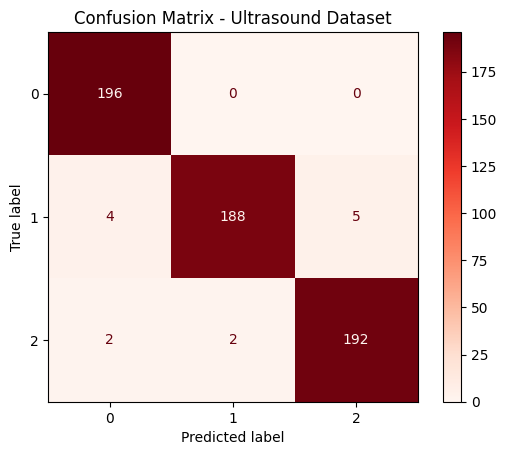

In [ ]:
# Testing the best model on the test set for DATASET 1
y_pred_ultrasound = best_knn_ultrasound.predict(X_test_ultrasound)

# Evaluate performance for ultrasound dataset
print("Accuracy (KNN):", accuracy_score(y_test_ultrasound, y_pred_ultrasound))
print("Classification Report (KNN):\n", classification_report(y_test_ultrasound, y_pred_ultrasound))

# Confusion Matrix for DATASET 1
cm = confusion_matrix(y_test_ultrasound, y_pred_ultrasound)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=best_knn_ultrasound.classes_)
disp.plot(cmap=plt.cm.Reds) 
plt.title("Confusion Matrix - Ultrasound Dataset")
plt.show()

#### Logistic regression

In [ ]:
# Define base Logistic Regression classifier for ultrasound dataset
log_reg_ultrasound = LogisticRegression(max_iter=1000)

# Define hyperparameter search space for GridSearchCV
param_grid_log_reg = {
    # Regularization strength (inverse of regularization parameter)
    'C': [0.01, 0.1, 1, 10, 100],
    # Type of regularization penalty
    'penalty': ['l2', 'l1'],
    # Solver compatible with chosen penalties
    'solver': ['liblinear']   # supports both l1 and l2
}

# Set up grid search with cross-validation
grid_search_log_reg_ultrasound = GridSearchCV(
    estimator=log_reg_ultrasound,   # model to tune
    param_grid=param_grid_log_reg,  # hyperparameters to explore
    cv=5,                           # 5-fold cross-validation
    scoring='accuracy',             # metric used to select best model
    n_jobs=-1                       # use all available CPU cores
)

# Run grid search on training data
grid_search_log_reg_ultrasound.fit(X_train_ultrasound, y_train_ultrasound)

# Extract best Logistic Regression model found during the search
best_log_reg_ultrasound = grid_search_log_reg_ultrasound.best_estimator_

# Print best hyperparameter combination
print("Best hyperparameters (Ultrasound - Logistic Regression):",
      grid_search_log_reg_ultrasound.best_params_)


C:\Users\213053\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\joblib\externals\loky\process_executor.py:752: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best hyperparameters (Ultrasound - Logistic Regression): {'C': 10, 'penalty': 'l1', 'solver': 'liblinear'}


Accuracy (Ultrasound - LogReg): 0.9779286926994907
Classification Report (Ultrasound - LogReg):
               precision    recall  f1-score   support

           0       0.99      0.99      0.99       196
           1       0.96      0.98      0.97       197
           2       0.98      0.96      0.97       196

    accuracy                           0.98       589
   macro avg       0.98      0.98      0.98       589
weighted avg       0.98      0.98      0.98       589



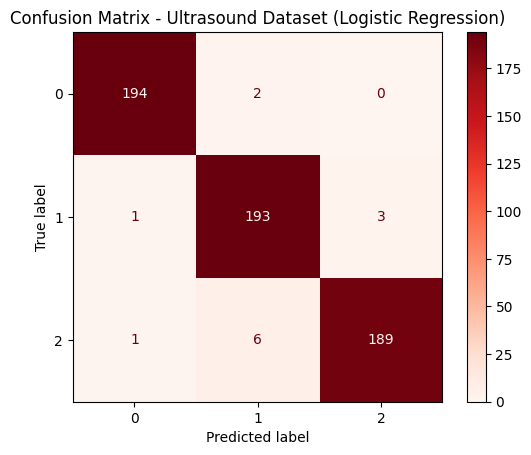

In [79]:
# Testing the best Logistic Regression model on the test set for DATASET 1
y_pred_ultrasound_logreg = best_log_reg_ultrasound.predict(X_test_ultrasound)

# Evaluate performance for ultrasound dataset (Logistic Regression)
print("Accuracy (Ultrasound - LogReg):", accuracy_score(y_test_ultrasound, y_pred_ultrasound_logreg))
print("Classification Report (Ultrasound - LogReg):\n",
      classification_report(y_test_ultrasound, y_pred_ultrasound_logreg))

# Confusion Matrix for DATASET 1 (Logistic Regression)
cm_logreg_ultrasound = confusion_matrix(y_test_ultrasound, y_pred_ultrasound_logreg)
disp_logreg_ultrasound = ConfusionMatrixDisplay(
    confusion_matrix=cm_logreg_ultrasound,
    display_labels=best_log_reg_ultrasound.classes_
)
disp_logreg_ultrasound.plot(cmap=plt.cm.Reds)
plt.title("Confusion Matrix - Ultrasound Dataset (Logistic Regression)")
plt.show()

#### Support Vector Machine

In [81]:
# Define base SVM classifier for ultrasound dataset
svm_ultrasound = SVC()

# Define hyperparameter search space for GridSearchCV
param_grid_svm = {
    # Kernel type to use in the algorithm
    'kernel': ['linear', 'rbf', 'poly'],
    # Regularization parameter
    'C': [0.1, 1, 10, 100],
    # Kernel coefficient for 'rbf' and 'poly'
    'gamma': ['scale', 'auto']
}

# Set up grid search with cross-validation
grid_search_svm_ultrasound = GridSearchCV(
    estimator=svm_ultrasound,   # model to tune
    param_grid=param_grid_svm,  # hyperparameters to explore
    cv=5,                       # 5-fold cross-validation
    scoring='accuracy',         # metric used to select best model
    n_jobs=-1                   # use all available CPU cores
)

# Run grid search on training data
grid_search_svm_ultrasound.fit(X_train_ultrasound, y_train_ultrasound)

# Extract best SVM model found during the search
best_svm_ultrasound = grid_search_svm_ultrasound.best_estimator_

# Print best hyperparameter combination
print("Best hyperparameters (Ultrasound - SVM):",
      grid_search_svm_ultrasound.best_params_)


Best hyperparameters (Ultrasound - SVM): {'C': 10, 'gamma': 'scale', 'kernel': 'poly'}


Accuracy (Ultrasound - SVM): 0.9898132427843803
Classification Report (Ultrasound - SVM):
               precision    recall  f1-score   support

           0       0.99      0.99      0.99       196
           1       0.98      1.00      0.99       197
           2       1.00      0.97      0.99       196

    accuracy                           0.99       589
   macro avg       0.99      0.99      0.99       589
weighted avg       0.99      0.99      0.99       589



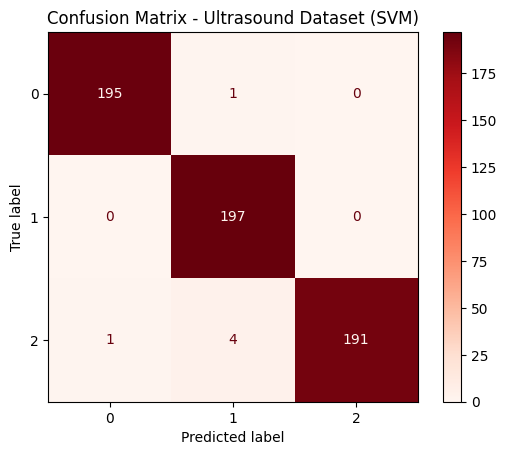

In [82]:
# Testing the best SVM model on the test set for DATASET 1
y_pred_ultrasound_svm = best_svm_ultrasound.predict(X_test_ultrasound)

# Evaluate performance for ultrasound dataset (SVM)
print("Accuracy (Ultrasound - SVM):", accuracy_score(y_test_ultrasound, y_pred_ultrasound_svm))
print("Classification Report (Ultrasound - SVM):\n",
      classification_report(y_test_ultrasound, y_pred_ultrasound_svm))

# Confusion Matrix for DATASET 1 (SVM)
cm_svm_ultrasound = confusion_matrix(y_test_ultrasound, y_pred_ultrasound_svm)
disp_svm_ultrasound = ConfusionMatrixDisplay(
    confusion_matrix=cm_svm_ultrasound,
    display_labels=best_svm_ultrasound.classes_
)
disp_svm_ultrasound.plot(cmap=plt.cm.Reds)
plt.title("Confusion Matrix - Ultrasound Dataset (SVM)")
plt.show()

#### Decision Tree

In [84]:
# Define base Decision Tree classifier for ultrasound dataset
dt_ultrasound = DecisionTreeClassifier(random_state=42)

# Define hyperparameter search space for GridSearchCV
param_grid_dt = {
    # Maximum depth of the tree
    'max_depth': [None, 5, 10, 20, 30],
    # Minimum number of samples required to split an internal node
    'min_samples_split': [2, 5, 10],
    # Minimum number of samples required to be at a leaf node
    'min_samples_leaf': [1, 2, 4],
    # Criterion to measure the quality of a split
    'criterion': ['gini', 'entropy']
}

# Set up grid search with cross-validation
grid_search_dt_ultrasound = GridSearchCV(
    estimator=dt_ultrasound,   # model to tune
    param_grid=param_grid_dt,  # hyperparameters to explore
    cv=5,                      # 5-fold cross-validation
    scoring='accuracy',        # metric used to select best model
    n_jobs=-1                  # use all available CPU cores
)

# Run grid search on training data
grid_search_dt_ultrasound.fit(X_train_ultrasound, y_train_ultrasound)

# Extract best Decision Tree model found during the search
best_dt_ultrasound = grid_search_dt_ultrasound.best_estimator_

# Print best hyperparameter combination
print("Best hyperparameters (Ultrasound - Decision Tree):",
      grid_search_dt_ultrasound.best_params_)

Best hyperparameters (Ultrasound - Decision Tree): {'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2}


Accuracy (Ultrasound - Decision Tree): 0.8777589134125636
Classification Report (Ultrasound - Decision Tree):
               precision    recall  f1-score   support

           0       0.94      0.92      0.93       196
           1       0.83      0.85      0.84       197
           2       0.86      0.86      0.86       196

    accuracy                           0.88       589
   macro avg       0.88      0.88      0.88       589
weighted avg       0.88      0.88      0.88       589



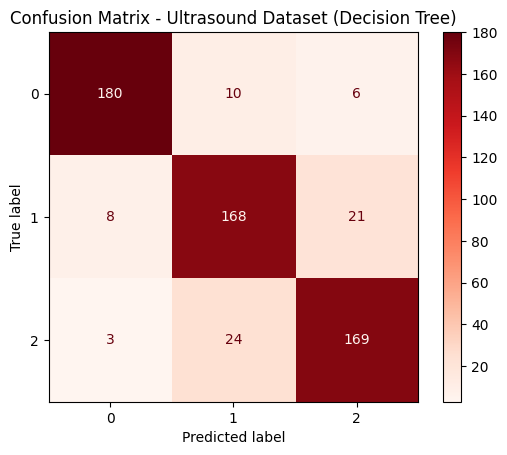

In [85]:
# Testing the best Decision Tree model on the test set for DATASET 1
y_pred_ultrasound_dt = best_dt_ultrasound.predict(X_test_ultrasound)

# Evaluate performance for ultrasound dataset (Decision Tree)
print("Accuracy (Ultrasound - Decision Tree):",
      accuracy_score(y_test_ultrasound, y_pred_ultrasound_dt))
print("Classification Report (Ultrasound - Decision Tree):\n",
      classification_report(y_test_ultrasound, y_pred_ultrasound_dt))

# Confusion Matrix for DATASET 1 (Decision Tree)
cm_dt_ultrasound = confusion_matrix(y_test_ultrasound, y_pred_ultrasound_dt)
disp_dt_ultrasound = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt_ultrasound,
    display_labels=best_dt_ultrasound.classes_
)
disp_dt_ultrasound.plot(cmap=plt.cm.Reds)
plt.title("Confusion Matrix - Ultrasound Dataset (Decision Tree)")
plt.show()

#### Random Forest

In [14]:
# Define base Random Forest classifier for Ultrasound dataset
rf_ultrasound = RandomForestClassifier(random_state=42, n_estimators=100)

# Define hyperparameter search space for GridSearchCV
param_grid_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2']
}

# Set up grid search with cross-validation
grid_search_rf_ultrasound = GridSearchCV(
    estimator=rf_ultrasound,
    param_grid=param_grid_rf,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

# Run grid search on training data
grid_search_rf_ultrasound.fit(X_train_ultrasound, y_train_ultrasound)

# Extract best Random Forest model
best_rf_ultrasound = grid_search_rf_ultrasound.best_estimator_

# Print best hyperparameter combination
print("Best hyperparameters (Ultrasound - Random Forest):",
      grid_search_rf_ultrasound.best_params_)


Best hyperparameters (Ultrasound - Random Forest): {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 300}


Accuracy (Ultrasound - Random Forest): 0.9796264855687606
Classification Report (Ultrasound - Random Forest):
               precision    recall  f1-score   support

           0       0.99      0.99      0.99       196
           1       0.96      0.98      0.97       197
           2       0.98      0.96      0.97       196

    accuracy                           0.98       589
   macro avg       0.98      0.98      0.98       589
weighted avg       0.98      0.98      0.98       589



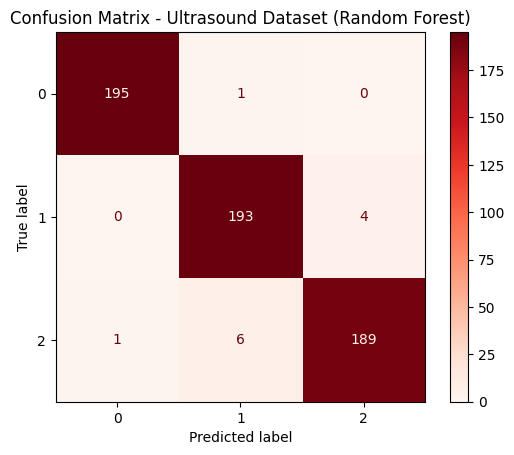

In [15]:
# Testing the best Random Forest model on the test set
y_pred_ultrasound_rf = best_rf_ultrasound.predict(X_test_ultrasound)

# Evaluate performance
print("Accuracy (Ultrasound - Random Forest):",
      accuracy_score(y_test_ultrasound, y_pred_ultrasound_rf))
print("Classification Report (Ultrasound - Random Forest):\n",
      classification_report(y_test_ultrasound, y_pred_ultrasound_rf))

# Confusion Matrix
cm_rf_ultrasound = confusion_matrix(y_test_ultrasound, y_pred_ultrasound_rf)
disp_rf_ultrasound = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf_ultrasound,
    display_labels=best_rf_ultrasound.classes_
)
disp_rf_ultrasound.plot(cmap=plt.cm.Reds)
plt.title("Confusion Matrix - Ultrasound Dataset (Random Forest)")
plt.show()


#### Linear Discriminant Analysis (LDA)

In [16]:
# Define base LDA classifier for Ultrasound dataset
lda_ultrasound = LinearDiscriminantAnalysis()

# Define hyperparameter search space for GridSearchCV
param_grid_lda = {
    'solver': ['lsqr', 'eigen'],
    'shrinkage': [None, 'auto', 0.1, 0.5],  # Only for 'lsqr' or 'eigen'
    'n_components': [1, 2, None]  # Only for multiclass
}

# Set up grid search with cross-validation
grid_search_lda_ultrasound = GridSearchCV(
    estimator=lda_ultrasound,
    param_grid=param_grid_lda,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

# Run grid search on training data
grid_search_lda_ultrasound.fit(X_train_ultrasound, y_train_ultrasound)

# Extract best LDA model
best_lda_ultrasound = grid_search_lda_ultrasound.best_estimator_

# Print best hyperparameter combination
print("Best hyperparameters (Ultrasound - LDA):",
      grid_search_lda_ultrasound.best_params_)


Best hyperparameters (Ultrasound - LDA): {'n_components': 1, 'shrinkage': 0.5, 'solver': 'lsqr'}


Accuracy (Ultrasound - LDA): 0.9796264855687606
Classification Report (Ultrasound - LDA):
               precision    recall  f1-score   support

           0       0.99      1.00      1.00       196
           1       0.97      0.97      0.97       197
           2       0.97      0.97      0.97       196

    accuracy                           0.98       589
   macro avg       0.98      0.98      0.98       589
weighted avg       0.98      0.98      0.98       589



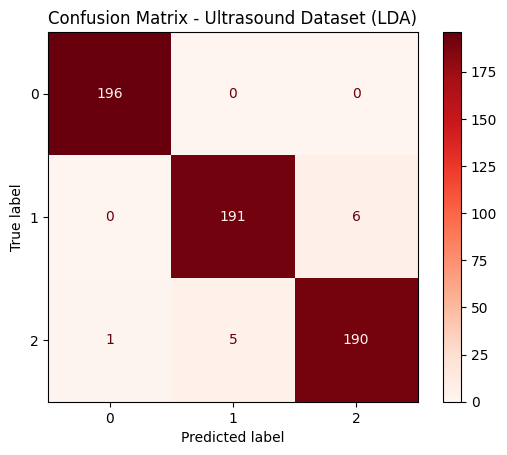

In [17]:
# Testing the best LDA model on the test set
y_pred_ultrasound_lda = best_lda_ultrasound.predict(X_test_ultrasound)

# Evaluate performance
print("Accuracy (Ultrasound - LDA):",
      accuracy_score(y_test_ultrasound, y_pred_ultrasound_lda))
print("Classification Report (Ultrasound - LDA):\n",
      classification_report(y_test_ultrasound, y_pred_ultrasound_lda))

# Confusion Matrix
cm_lda_ultrasound = confusion_matrix(y_test_ultrasound, y_pred_ultrasound_lda)
disp_lda_ultrasound = ConfusionMatrixDisplay(
    confusion_matrix=cm_lda_ultrasound,
    display_labels=best_lda_ultrasound.classes_
)
disp_lda_ultrasound.plot(cmap=plt.cm.Reds)
plt.title("Confusion Matrix - Ultrasound Dataset (LDA)")
plt.show()

### Dataset 2: Fetal Brain Standard Planes

#### K-nearest neighbors

In [73]:
# Define base KNN classifier 
knn_brain = KNeighborsClassifier()

# Define hyperparameter search space for GridSearchCV (same grid as Dataset 1)
param_grid_brain = {
    # Number of neighbors to consider
    'n_neighbors': [3, 5, 7, 9, 11, 13, 15],
    # Weighting scheme: all neighbors equal or distance-weighted
    'weights': ['uniform', 'distance'],
    # Distance metric to use
    'metric': ['euclidean', 'manhattan', 'minkowski']
}

# Set up grid search with cross-validation for Brain dataset
grid_search_brain = GridSearchCV(
    estimator=knn_brain,        # model to tune for brain features
    param_grid=param_grid_brain, # hyperparameters to explore
    cv=5,                        # 5-fold cross-validation
    scoring='accuracy',          # metric used to select best model
    n_jobs=-1                    # use all available CPU cores
)

# Run grid search on training data of Brain dataset
grid_search_brain.fit(X_train_brain, y_train_brain)

# Extract best KNN model found during the search
best_knn_brain = grid_search_brain.best_estimator_

# Print best hyperparameter combination for Brain dataset
print("Best hyperparameters (Brain):", grid_search_brain.best_params_)

Best hyperparameters (Brain): {'metric': 'manhattan', 'n_neighbors': 11, 'weights': 'distance'}


Accuracy (Brain): 0.652542372881356
Classification Report (Brain):
               precision    recall  f1-score   support

           0       0.64      0.65      0.64       118
           1       0.70      0.45      0.55       118
           2       0.64      0.86      0.73       118

    accuracy                           0.65       354
   macro avg       0.66      0.65      0.64       354
weighted avg       0.66      0.65      0.64       354



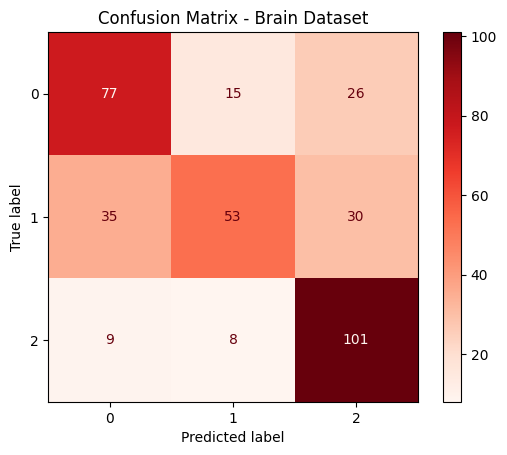

In [74]:
# Testing the best model on the test set for DATASET 2 (Brain)
y_pred_brain = best_knn_brain.predict(X_test_brain)

# Evaluate performance on Brain dataset
print("Accuracy (Brain):", accuracy_score(y_test_brain, y_pred_brain))
print("Classification Report (Brain):\n", classification_report(y_test_brain, y_pred_brain))

# Confusion Matrix for DATASET 2 
cm_brain = confusion_matrix(y_test_brain, y_pred_brain)
disp_brain = ConfusionMatrixDisplay(confusion_matrix=cm_brain,
                                    display_labels=best_knn_brain.classes_)
disp_brain.plot(cmap=plt.cm.Reds)
plt.title("Confusion Matrix - Brain Dataset")
plt.show()

#### Logistic regression

In [88]:
# Define base Logistic Regression classifier for brain dataset
log_reg_brain = LogisticRegression(max_iter=1000)

# Define hyperparameter search space for GridSearchCV
param_grid_log_reg = {
    # Regularization strength (inverse of regularization parameter)
    'C': [0.01, 0.1, 1, 10, 100],
    # Type of regularization penalty
    'penalty': ['l2', 'l1'],
    # Solver compatible with chosen penalties
    'solver': ['liblinear']   # supports both l1 and l2
}

# Set up grid search with cross-validation
grid_search_log_reg_brain = GridSearchCV(
    estimator=log_reg_brain,   # model to tune
    param_grid=param_grid_log_reg,  # hyperparameters to explore
    cv=5,                           # 5-fold cross-validation
    scoring='accuracy',             # metric used to select best model
    n_jobs=-1                       # use all available CPU cores
)

# Run grid search on training data
grid_search_log_reg_brain.fit(X_train_brain, y_train_brain)

# Extract best Logistic Regression model found during the search
best_log_reg_brain = grid_search_log_reg_brain.best_estimator_

# Print best hyperparameter combination
print("Best hyperparameters (Brain - Logistic Regression):",
      grid_search_log_reg_ultrasound.best_params_)


Best hyperparameters (Brain - Logistic Regression): {'C': 10, 'penalty': 'l1', 'solver': 'liblinear'}


Accuracy (Brain - LogReg): 0.5932203389830508
Classification Report (Brain - LogReg):
               precision    recall  f1-score   support

           0       0.59      0.58      0.59       118
           1       0.60      0.48      0.54       118
           2       0.59      0.71      0.65       118

    accuracy                           0.59       354
   macro avg       0.59      0.59      0.59       354
weighted avg       0.59      0.59      0.59       354



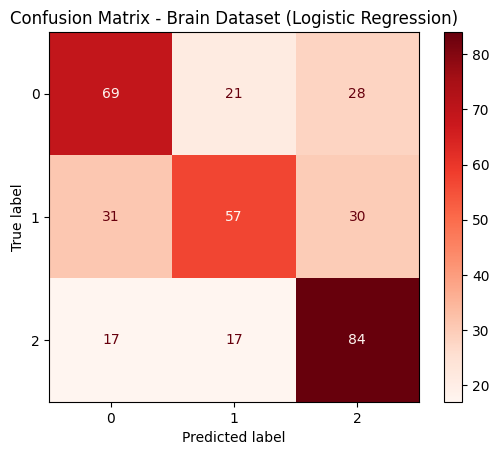

In [ ]:
# Testing the best Logistic Regression model on the test set for DATASET 2
y_pred_brain_logreg = best_log_reg_brain.predict(X_test_brain)

# Evaluate performance for brain dataset (Logistic Regression)
print("Accuracy (Brain - LogReg):", accuracy_score(y_test_brain, y_pred_brain_logreg))
print("Classification Report (Brain - LogReg):\n",
      classification_report(y_test_brain, y_pred_brain_logreg))

# Confusion Matrix for DATASET 2 (Logistic Regression)
cm_logreg_brain = confusion_matrix(y_test_brain, y_pred_brain_logreg)
disp_logreg_brain = ConfusionMatrixDisplay(
    confusion_matrix=cm_logreg_brain,
    display_labels=best_log_reg_brain.classes_
)
disp_logreg_brain.plot(cmap=plt.cm.Reds)
plt.title("Confusion Matrix - Brain Dataset (Logistic Regression)")
plt.show()

#### Support Vector Machine

In [90]:
# Define base SVM classifier for ultrasound dataset
svm_brain = SVC()

# Define hyperparameter search space for GridSearchCV
param_grid_svm = {
    # Kernel type to use in the algorithm
    'kernel': ['linear', 'rbf', 'poly'],
    # Regularization parameter
    'C': [0.1, 1, 10, 100],
    # Kernel coefficient for 'rbf' and 'poly'
    'gamma': ['scale', 'auto']
}

# Set up grid search with cross-validation
grid_search_svm_brain = GridSearchCV(
    estimator=svm_brain,   # model to tune
    param_grid=param_grid_svm,  # hyperparameters to explore
    cv=5,                       # 5-fold cross-validation
    scoring='accuracy',         # metric used to select best model
    n_jobs=-1                   # use all available CPU cores
)

# Run grid search on training data
grid_search_svm_brain.fit(X_train_brain, y_train_brain)

# Extract best SVM model found during the search
best_svm_brain = grid_search_svm_brain.best_estimator_

# Print best hyperparameter combination
print("Best hyperparameters (Brain - SVM):",
      grid_search_svm_brain.best_params_)


Best hyperparameters (Brain - SVM): {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}


Accuracy (Brain - SVM): 0.6666666666666666
Classification Report (Brain - SVM):
               precision    recall  f1-score   support

           0       0.62      0.70      0.66       118
           1       0.67      0.53      0.59       118
           2       0.71      0.77      0.74       118

    accuracy                           0.67       354
   macro avg       0.67      0.67      0.66       354
weighted avg       0.67      0.67      0.66       354



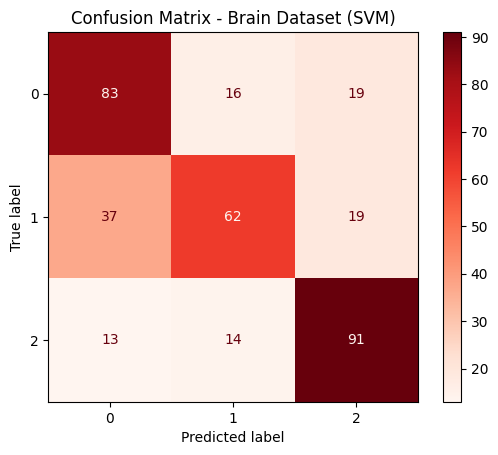

In [92]:
# Testing the best SVM model on the test set for DATASET 2
y_pred_brain_svm = best_svm_brain.predict(X_test_brain)

# Evaluate performance for brain dataset (SVM)
print("Accuracy (Brain - SVM):", accuracy_score(y_test_brain, y_pred_brain_svm))
print("Classification Report (Brain - SVM):\n",
      classification_report(y_test_brain, y_pred_brain_svm))

# Confusion Matrix for DATASET 2 (SVM)
cm_svm_brain = confusion_matrix(y_test_brain, y_pred_brain_svm)
disp_svm_brain = ConfusionMatrixDisplay(
    confusion_matrix=cm_svm_brain,
    display_labels=best_svm_brain.classes_
)
disp_svm_brain.plot(cmap=plt.cm.Reds)
plt.title("Confusion Matrix - Brain Dataset (SVM)")
plt.show()

#### Decision tree

In [93]:
# Define base Decision Tree classifier for ultrasound dataset
dt_brain = DecisionTreeClassifier(random_state=42)

# Define hyperparameter search space for GridSearchCV
param_grid_dt = {
    # Maximum depth of the tree
    'max_depth': [None, 5, 10, 20, 30],
    # Minimum number of samples required to split an internal node
    'min_samples_split': [2, 5, 10],
    # Minimum number of samples required to be at a leaf node
    'min_samples_leaf': [1, 2, 4],
    # Criterion to measure the quality of a split
    'criterion': ['gini', 'entropy']
}

# Set up grid search with cross-validation
grid_search_dt_brain = GridSearchCV(
    estimator=dt_brain,   # model to tune
    param_grid=param_grid_dt,  # hyperparameters to explore
    cv=5,                      # 5-fold cross-validation
    scoring='accuracy',        # metric used to select best model
    n_jobs=-1                  # use all available CPU cores
)

# Run grid search on training data
grid_search_dt_brain.fit(X_train_brain, y_train_brain)

# Extract best Decision Tree model found during the search
best_dt_brain = grid_search_dt_brain.best_estimator_

# Print best hyperparameter combination
print("Best hyperparameters (Brain - Decision Tree):",
      grid_search_dt_brain.best_params_)

Best hyperparameters (Brain - Decision Tree): {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2}


Accuracy (Brain - Decision Tree): 0.5
Classification Report (Brain - Decision Tree):
               precision    recall  f1-score   support

           0       0.48      0.41      0.44       118
           1       0.46      0.44      0.45       118
           2       0.55      0.65      0.59       118

    accuracy                           0.50       354
   macro avg       0.50      0.50      0.50       354
weighted avg       0.50      0.50      0.50       354



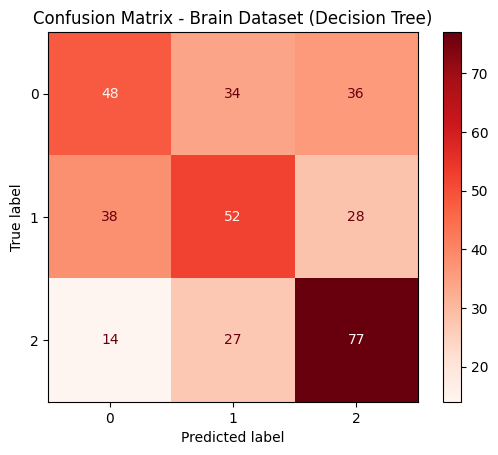

In [94]:
# Testing the best Decision Tree model on the test set for DATASET 2
y_pred_brain_dt = best_dt_brain.predict(X_test_brain)

# Evaluate performance for braind dataset (Decision Tree)
print("Accuracy (Brain - Decision Tree):",
      accuracy_score(y_test_brain, y_pred_brain_dt))
print("Classification Report (Brain - Decision Tree):\n",
      classification_report(y_test_brain, y_pred_brain_dt))

# Confusion Matrix for DATASET 2 (Decision Tree)
cm_dt_brain = confusion_matrix(y_test_brain, y_pred_brain_dt)
disp_dt_brain = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt_brain,
    display_labels=best_dt_brain.classes_
)
disp_dt_brain.plot(cmap=plt.cm.Reds)
plt.title("Confusion Matrix - Brain Dataset (Decision Tree)")
plt.show()

#### Random Forest

In [18]:
# Define base Random Forest classifier for Brain dataset
rf_brain = RandomForestClassifier(random_state=42, n_estimators=100)

# Define hyperparameter search space for GridSearchCV
param_grid_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2']
}

# Set up grid search with cross-validation
grid_search_rf_brain = GridSearchCV(
    estimator=rf_brain,
    param_grid=param_grid_rf,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

# Run grid search on training data
grid_search_rf_brain.fit(X_train_brain, y_train_brain)

# Extract best Random Forest model
best_rf_brain = grid_search_rf_brain.best_estimator_

# Print best hyperparameter combination
print("Best hyperparameters (Brain - Random Forest):",
      grid_search_rf_brain.best_params_)

Best hyperparameters (Brain - Random Forest): {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 200}


Accuracy (Brain - Random Forest): 0.6440677966101694
Classification Report (Brain - Random Forest):
               precision    recall  f1-score   support

           0       0.64      0.67      0.65       118
           1       0.62      0.45      0.52       118
           2       0.67      0.81      0.73       118

    accuracy                           0.64       354
   macro avg       0.64      0.64      0.64       354
weighted avg       0.64      0.64      0.64       354



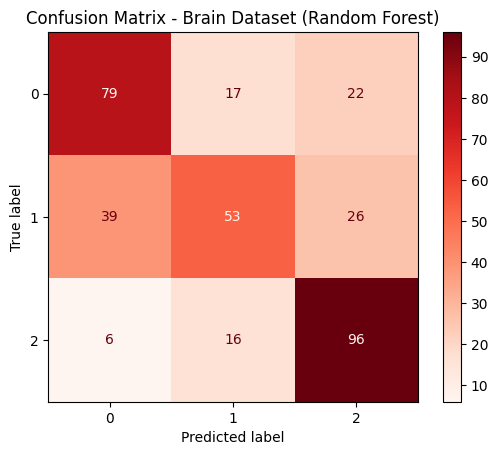

In [19]:
# Testing the best Random Forest model on the test set
y_pred_brain_rf = best_rf_brain.predict(X_test_brain)

# Evaluate performance
print("Accuracy (Brain - Random Forest):",
      accuracy_score(y_test_brain, y_pred_brain_rf))
print("Classification Report (Brain - Random Forest):\n",
      classification_report(y_test_brain, y_pred_brain_rf))

# Confusion Matrix
cm_rf_brain = confusion_matrix(y_test_brain, y_pred_brain_rf)
disp_rf_brain = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf_brain,
    display_labels=best_rf_brain.classes_
)
disp_rf_brain.plot(cmap=plt.cm.Reds)
plt.title("Confusion Matrix - Brain Dataset (Random Forest)")
plt.show()

#### Linear Discriminant Analysis (LDA)

In [21]:
# Define base LDA classifier for Brain dataset
lda_brain = LinearDiscriminantAnalysis()

# Define hyperparameter search space for GridSearchCV
param_grid_lda = {
    'solver': ['lsqr', 'eigen'],
    'shrinkage': [None, 'auto', 0.1, 0.5],  # Only for 'lsqr' or 'eigen'
}

# Set up grid search with cross-validation
grid_search_lda_brain = GridSearchCV(
    estimator=lda_brain,
    param_grid=param_grid_lda,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

# Run grid search on training data
grid_search_lda_brain.fit(X_train_brain, y_train_brain)

# Extract best LDA model
best_lda_brain = grid_search_lda_brain.best_estimator_

# Print best hyperparameter combination
print("Best hyperparameters (Brain - LDA):",
      grid_search_lda_brain.best_params_)


C:\Users\213053\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\model_selection\_validation.py:528: FitFailedWarning: 
5 fits failed out of a total of 40.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
1 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\213053\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\model_selection\_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "C:\Users\213053\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-pac

Best hyperparameters (Brain - LDA): {'shrinkage': 0.5, 'solver': 'lsqr'}


Accuracy (Brain - LDA): 0.6016949152542372
Classification Report (Brain - LDA):
               precision    recall  f1-score   support

           0       0.59      0.60      0.59       118
           1       0.60      0.49      0.54       118
           2       0.61      0.71      0.66       118

    accuracy                           0.60       354
   macro avg       0.60      0.60      0.60       354
weighted avg       0.60      0.60      0.60       354



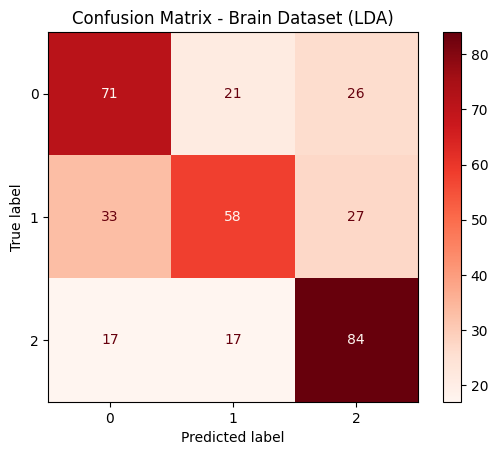

In [22]:
# Testing the best LDA model on the test set
y_pred_brain_lda = best_lda_brain.predict(X_test_brain)

# Evaluate performance
print("Accuracy (Brain - LDA):",
      accuracy_score(y_test_brain, y_pred_brain_lda))
print("Classification Report (Brain - LDA):\n",
      classification_report(y_test_brain, y_pred_brain_lda))

# Confusion Matrix
cm_lda_brain = confusion_matrix(y_test_brain, y_pred_brain_lda)
disp_lda_brain = ConfusionMatrixDisplay(
    confusion_matrix=cm_lda_brain,
    display_labels=best_lda_brain.classes_
)
disp_lda_brain.plot(cmap=plt.cm.Reds)
plt.title("Confusion Matrix - Brain Dataset (LDA)")
plt.show()
